# A tutorial on `solver1d`

`solver1d.py` computes the wave-optics amplification factor of an arbitrary **axisymmetric** lens with a lensing potential $\psi(x)$. It solves the Fresnel–Kirchhoff diffraction integral:

$$
F(w, y) = -i\,w\,e^{i w y^2/2}\int_0^\infty J_0(w\,y\,x)\;e^{\,i w\,[\,x^2/2 - \psi(x)\,]}\;x\,dx ,
$$

with $w$ the dimensionless frequency and $y$ the dimensionless source position. It integrates along a rotated contour (head + tail), so the same machinery works for any $\psi(x)$ you can write down analytically.

**In this notebook:**

1. Setup and the API at a glance
2. Built-in lenses: Point mass, SIS, CIS, NFW, Plummer sphere, Power law, Mass sheet
3. Source-position dependence: profiles and $(w, y)$ maps
4. Reusing a `Solver1D` object
5. Building a new lens
6. Accuracy checks


## 1. Setup

`solver1d.py` must be in the same folder as the notebook (or on `sys.path`). `finufft` is optional: with it, many-frequency spectra use fast non-uniform FFTs; without it the code falls back to direct sums (same answer, slower).

In [4]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt

from gwlens import solver1d as s1d
from gwlens.tools import plotting
plotting.apply_figure_style()
print("finufft available:", s1d.finufft is not None)
print("cores available  :", s1d.available_cores())

finufft available: True
cores available  : 8


### The API at a glance

| What you want | Function | Returns |
|---|---|---|
| one $w$, one $y$ | `amplification(w, y, lens)` | complex number |
| many $w$, one $y$ | `amplification_many(ws, y, lens)` | array `(len(ws),)` |
| one $w$, many $y$ | `amplification_profile(w, ys, lens)` | array `(len(ys),)` |
| many $w$, many $y$ | `amplification_grid(ws, ys, lens)` | array `(len(ys), len(ws))` |

All four build a `Solver1D` internally. If you evaluate many times (e.g. in a sampler), build the solver once and call it repeatedly. See section 4.

Lenses are `Potential` objects and can be **added** with `+`.

## 2. Built-in lenses

### 2.1 Point mass

### Theory: point mass

<br><br><br>

In [6]:
y = 0.5
lens = s1d.point_mass(1.0)                      # psi = m ln x

# one frequency, one source position
F_single = s1d.amplification(5.0, y, lens)
print("F(w=5, y=0.5) =", F_single)

# many frequencies, one source position
ws = np.geomspace(0.05, 100, 400)
F_pm = s1d.amplification_many(ws, y, lens)

F(w=5, y=0.5) = (0.5557627136040446-0.01981292435050619j)


For the point mass there is a closed form (in terms of $\Gamma$ and ${}_1F_1$), which makes it a good validation of the solver. We evaluate it with `mpmath`.

> **Phase convention.** The textbook formula multiplies $F$ by $e^{-iw\phi_m(y)}$, which measures time delays from the minimum-delay image. `solver1d` uses the raw Fermat potential $T = (x-y)^2/2 - \psi(x)$ with no such shift, so that factor is dropped below. $|F|$ is unaffected; only the overall phase differs.

In [7]:
import mpmath as mp

def F_point_mass_exact(w, y):
    """Analytic amplification factor of a point mass (m = 1), with the time delay
    measured from the raw Fermat potential (x-y)^2/2 - ln x, as in solver1d."""
    val = (mp.exp(mp.pi * w / 4 + 0.5j * w * mp.log(w / 2))
           * mp.gamma(1 - 0.5j * w) * mp.hyp1f1(0.5j * w, 1, 0.5j * w * y * y))
    return complex(val)

ws_check = ws[::8]
F_exact = np.array([F_point_mass_exact(w, y) for w in ws_check])
F_num = s1d.amplification_many(ws_check, y, lens)
print("max |F_solver - F_exact| =", np.max(np.abs(F_num - F_exact)))

max |F_solver - F_exact| = 4.872905322825206e-14


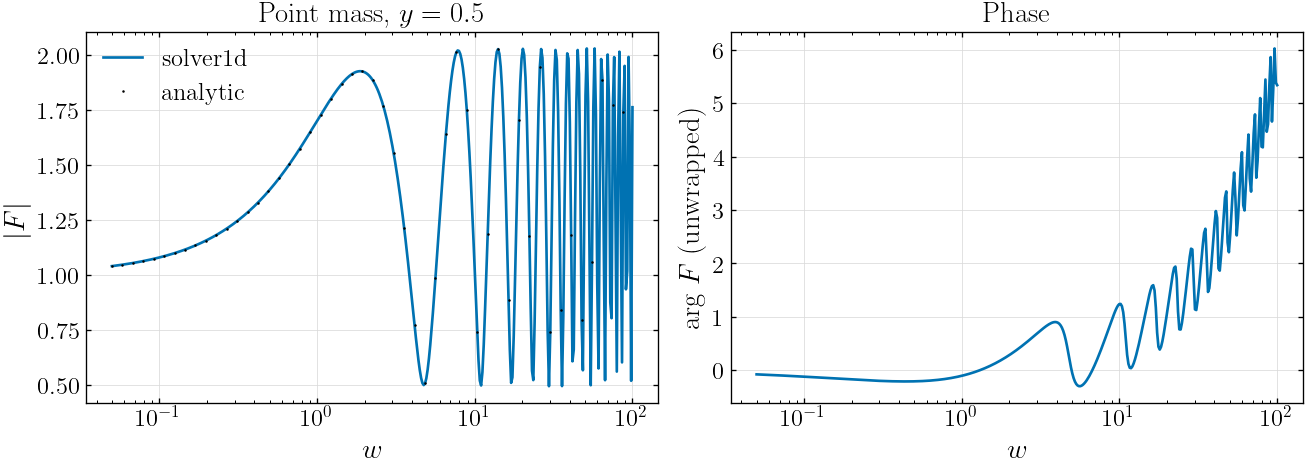

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogx(ws, np.abs(F_pm), label="solver1d")
ax[0].semilogx(ws_check, np.abs(F_exact), "k.", ms=3, label="analytic")
ax[0].set(xlabel="$w$", ylabel="$|F|$", title=f"Point mass, $y={y}$")
ax[0].legend()

ax[1].semilogx(ws, np.unwrap(np.angle(F_pm)))
ax[1].set(xlabel="$w$", ylabel="arg $F$ (unwrapped)", title="Phase")
plt.show()

### 2.2 Singular isothermal sphere (SIS)

### Theory: SIS

<br><br><br>

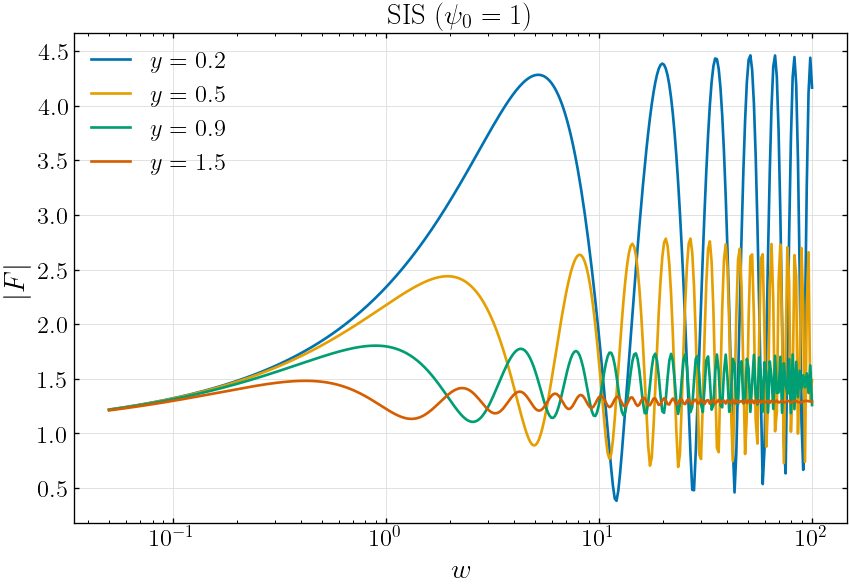

In [9]:
ws = np.geomspace(0.05, 100, 400)
fig, ax = plt.subplots()
for y in (0.2, 0.5, 0.9, 1.5):
    F = s1d.amplification_many(ws, y, s1d.sis(1.0))
    ax.semilogx(ws, np.abs(F), label=f"$y={y}$")
ax.set(xlabel="$w$", ylabel="$|F|$", title="SIS ($\\psi_0 = 1$)")
ax.legend(); plt.show()

### 2.3 Cored isothermal sphere (CIS)

### Theory: cored isothermal sphere

$\psi(x) = \psi_0\,[\,r + r_c\ln(2r_c/(r+r_c))\,]$, $r=\sqrt{x^2+r_c^2}$

<br><br><br>

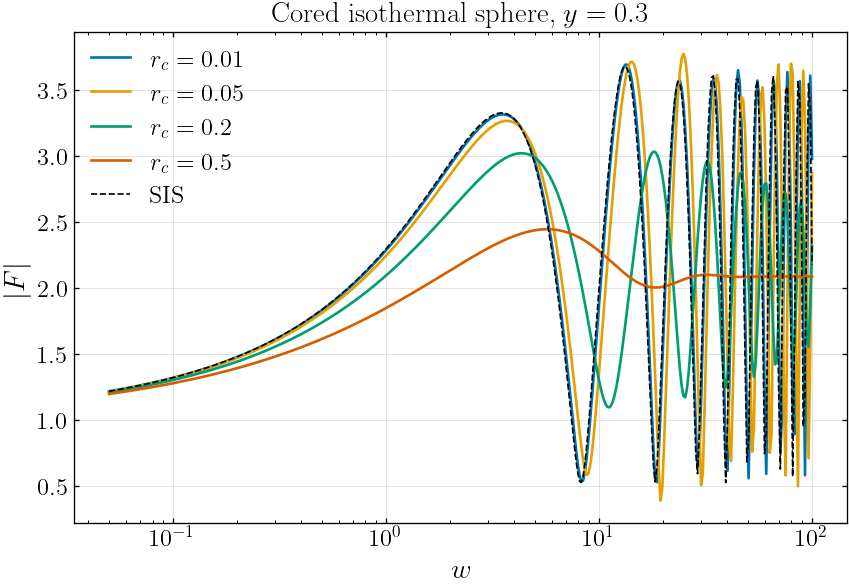

In [10]:
y = 0.3
fig, ax = plt.subplots()
for rc in (0.01, 0.05, 0.2, 0.5):
    F = s1d.amplification_many(ws, y, s1d.cis(psi0=1.0, rc=rc))
    ax.semilogx(ws, np.abs(F), label=f"$r_c={rc}$")
F = s1d.amplification_many(ws, y, s1d.sis(1.0))
ax.semilogx(ws, np.abs(F), "k--", lw=1, label="SIS")
ax.set(xlabel="$w$", ylabel="$|F|$", title=f"Cored isothermal sphere, $y={y}$")
ax.legend(); plt.show()

### 2.4 NFW

### Theory: NFW

$\psi(x) = \tfrac12\psi_0[\ln^2(kx/2) + \mathrm{arccos}^2(1/kx)]$, $k=\xi_0/r_s$

<br><br><br>

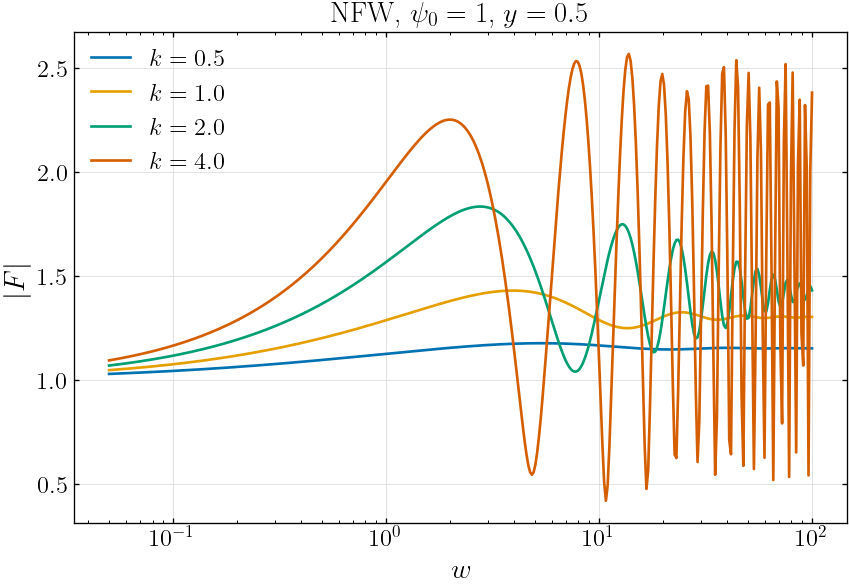

In [11]:
y = 0.5
fig, ax = plt.subplots()
for k in (0.5, 1.0, 2.0, 4.0):
    F = s1d.amplification_many(ws, y, s1d.nfw(k=k, psi0=1.0))
    ax.semilogx(ws, np.abs(F), label=f"$k={k}$")
ax.set(xlabel="$w$", ylabel="$|F|$", title=f"NFW, $\\psi_0=1$, $y={y}$")
ax.legend(); plt.show()

### 2.5 Power law

### Theory: power law

$\psi(x) = \psi_0\,x^p/p$ with $0<p<2$, $p=1$ is the SIS

<br><br><br>

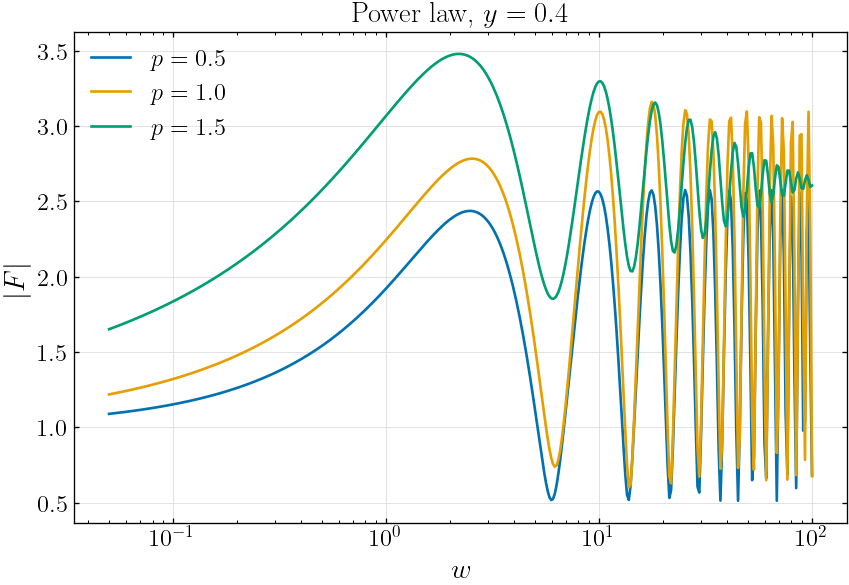

In [12]:
y = 0.4
fig, ax = plt.subplots()
for p in (0.5, 1.0, 1.5):
    F = s1d.amplification_many(ws, y, s1d.power_law(psi0=1.0, p=p))
    ax.semilogx(ws, np.abs(F), label=f"$p={p}$")
ax.set(xlabel="$w$", ylabel="$|F|$", title=f"Power law, $y={y}$")
ax.legend(); plt.show()

### 2.6 Mass sheet and combining lenses

### Theory: mass sheet

<br><br><br>

Potentials add with `+`, so a point mass embedded in a uniform sheet is just `point_mass(1.0) + mass_sheet(kappa)`.

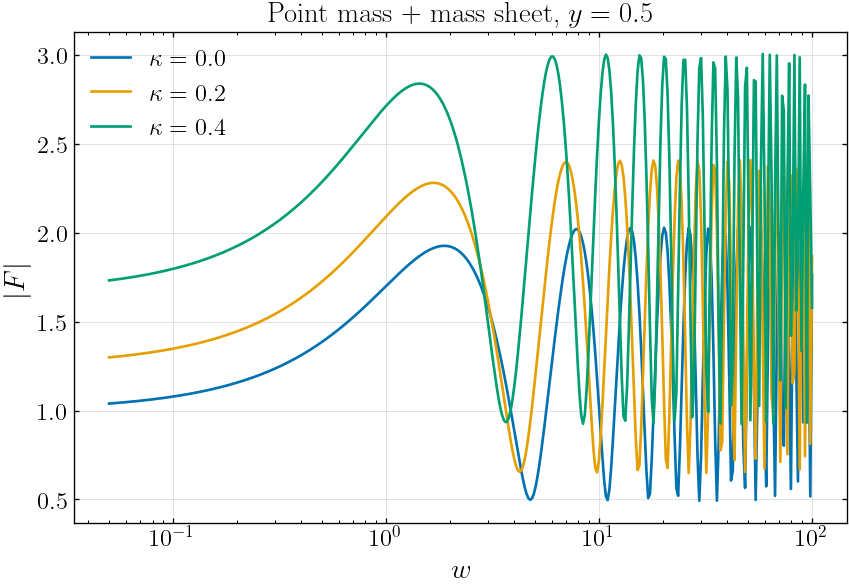

In [13]:
y = 0.5
fig, ax = plt.subplots()
for kappa in (0.0, 0.2, 0.4):
    lens = s1d.point_mass(1.0) + s1d.mass_sheet(kappa) if kappa else s1d.point_mass(1.0)
    F = s1d.amplification_many(ws, y, lens)
    ax.semilogx(ws, np.abs(F), label=f"$\\kappa={kappa}$")
ax.set(xlabel="$w$", ylabel="$|F|$", title=f"Point mass + mass sheet, $y={y}$")
ax.legend(); plt.show()

## 3. Source-position dependence

`amplification_profile` fixes $w$ and scans $y$; `amplification_grid` returns the full $(y, w)$ table.

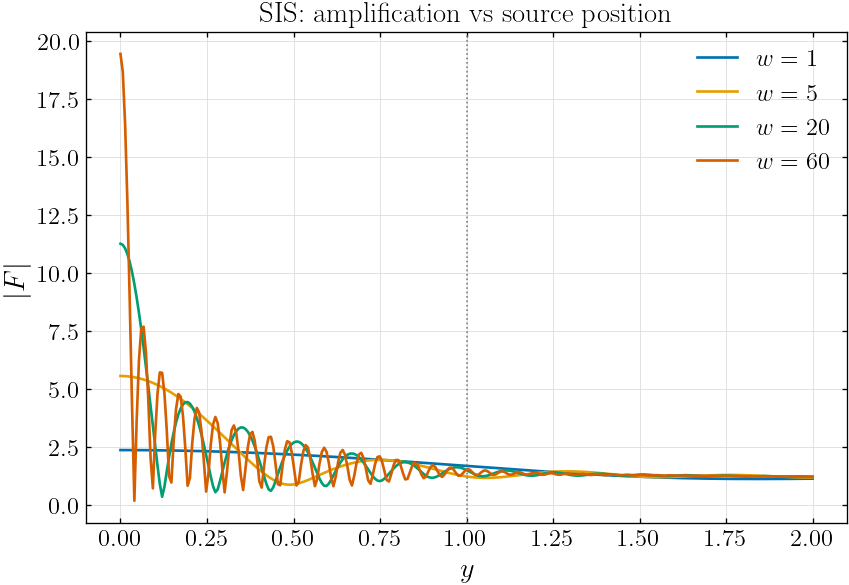

In [14]:
lens = s1d.sis(1.0)
ys = np.linspace(0.0, 2.0, 300)

fig, ax = plt.subplots()
for w in (1.0, 5.0, 20.0, 60.0):
    Fy = s1d.amplification_profile(w, ys, lens)
    ax.plot(ys, np.abs(Fy), label=f"$w={w:g}$")
ax.axvline(1.0, color="gray", ls=":", lw=1)
ax.set(xlabel="$y$", ylabel="$|F|$", title="SIS: amplification vs source position")
ax.legend(); plt.show()

grid (120, 200) computed in 3.08 s


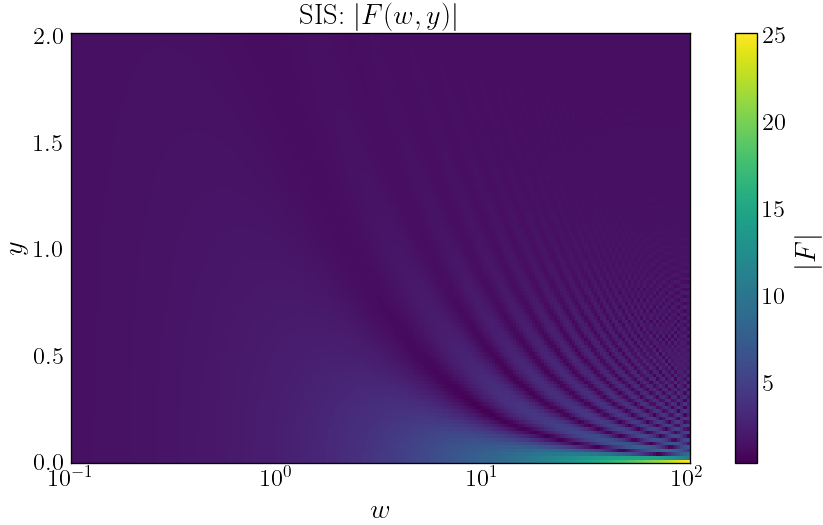

In [15]:
ws_g = np.geomspace(0.1, 100, 200)
ys_g = np.linspace(0.0, 2.0, 120)

t0 = time.perf_counter()
Fg = s1d.amplification_grid(ws_g, ys_g, lens)          # shape (len(ys), len(ws))
print(f"grid {Fg.shape} computed in {time.perf_counter() - t0:.2f} s")

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.pcolormesh(ws_g, ys_g, np.abs(Fg), shading="auto", cmap="viridis")
ax.set_xscale("log")
ax.set(xlabel="$w$", ylabel="$y$", title="SIS: $|F(w, y)|$")
ax.grid(False)
fig.colorbar(im, label="$|F|$"); plt.show()

## 4. Re-using a `Solver1D` object

The convenience functions rebuild the solver on every call. When you query the same lens many times, build it once. The expensive set-up (nodes, weights, tail) depends only on the lens, the frequency range `[wmin, wmax]` and the source-position range `y0 ± y_radius`.

In [16]:
lens = s1d.nfw(k=1.0, psi0=1.0)

# valid for all frequencies in [0.1, 1000] and source positions 0 <= y <= 1
solver = s1d.Solver1D(lens, y=0.5, wmin=0.1, wmax=1000, y_radius=0.5)
print("split radius x_b :", round(solver.info["x_b"], 2))
print("frequency bands  :", len(solver.info["bands"]))
print("total nodes      :", solver.info["n_nodes"])

split radius x_b : 3.0
frequency bands  : 7
total nodes      : 16576


In [17]:
ws = np.geomspace(0.1, 1000, 2000)

F_a = solver(5.0, 0.3)                     # single (w, y)
F_b = solver.spectrum(ws, 0.3)             # many w, one y
F_c = solver.profile(10.0, np.linspace(0, 1, 50))   # one w, many y
F_d = solver.evaluate(ws[::40], np.linspace(0, 1, 6))   # table (len(ys), len(ws))
print(F_b.shape, F_c.shape, F_d.shape)

# timing: repeated calls cost only the evaluation, not the set-up
t0 = time.perf_counter()
for y in np.linspace(0, 1, 20):
    solver.spectrum(ws, y)
print(f"20 spectra x {ws.size} frequencies: {time.perf_counter() - t0:.2f} s")

(2000,) (50,) (6, 50)
20 spectra x 2000 frequencies: 1.12 s


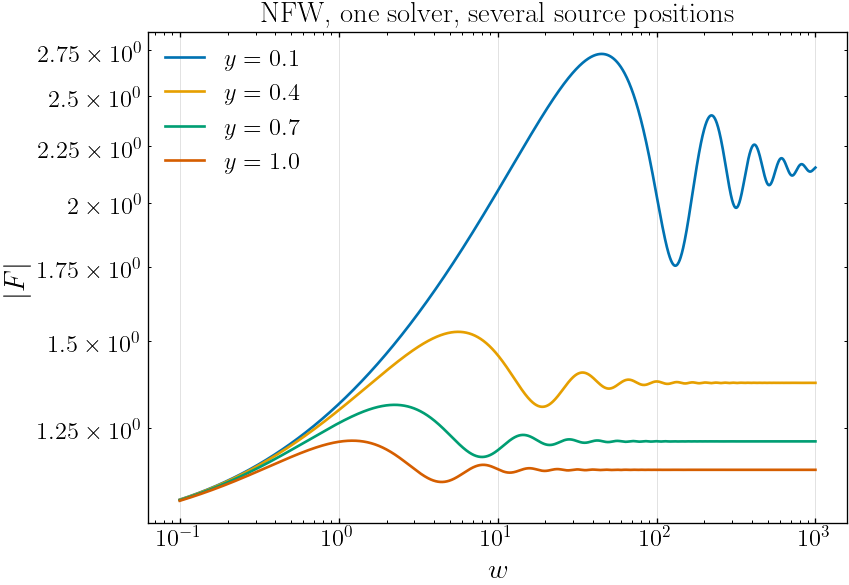

In [18]:
fig, ax = plt.subplots()
for y in (0.1, 0.4, 0.7, 1.0):
    ax.loglog(ws, np.abs(solver.spectrum(ws, y)), label=f"$y={y}$")
ax.set(xlabel="$w$", ylabel="$|F|$", title="NFW, one solver, several source positions")
ax.legend(); plt.show()

> Asking for a $y$ or $w$ outside the range the solver was built for raises a `ValueError`. Increase `y_radius` or the frequency range when building it.

## 5. Building a new lens

A lens is just a `Potential(psi)`, where `psi(x)` is the lensing potential as a function of the radius $x$. The solver rotates the tail of the integral into the complex plane, so `psi` is evaluated at **complex** $x$. That gives one rule:

> Write `psi` with **analytic** numpy operations only: `+ - * / **`, `np.log`, `np.sqrt`, `np.exp`, `np.arccos`, `np.arcsinh`, …
> **Avoid** `np.abs`, `np.hypot`, `np.maximum`, `np.where`, `np.real`, and `if/else` on `x`.

Optional arguments:

* `psi_real`: a faster version for real $x>0$ (use it if `psi` needs complex intermediates on the real axis, as NFW does).
* `q_inf`: $\lim_{x\to\infty}\psi'(x)/x$ (a mass sheet $\kappa$). Estimated numerically if omitted; passing it avoids the estimate.

### 5.1 Step 1: wrap a function, and check it against a built-in

In [19]:
my_sis = s1d.Potential(lambda x: 1.0 * x)       # same potential as sis(1.0)

ws = np.geomspace(0.05, 100, 300)
F_mine = s1d.amplification_many(ws, 0.5, my_sis)
F_ref = s1d.amplification_many(ws, 0.5, s1d.sis(1.0))
print("max |F_mine - F_builtin| =", np.max(np.abs(F_mine - F_ref)))

max |F_mine - F_builtin| = 0.0


### 5.2 Step 2: a genuinely new lens (Plummer-type softened point mass)

### Theory: the new lens

define the model you are adding, its parameters, $\psi(x)$, limits that recover known lenses

<br><br><br>

As an example we use $\psi(x) = \tfrac{m}{2}\ln(x^2 + r_c^2)$, which tends to the point mass for $r_c\to 0$. Wrapping it in a factory function keeps the parameters explicit:

In [20]:
def plummer(m=1.0, rc=0.1):
    """psi = (m/2) ln(x^2 + rc^2): softened point mass."""
    m, rc = float(m), float(rc)
    psi = lambda x: 0.5 * m * np.log(x * x + rc * rc)
    return s1d.Potential(psi, q_inf=0.0)        # psi'/x = m/(x^2+rc^2) -> 0 at large x

lens_new = plummer(1.0, 0.1)
lens_new.check_analytic(verbose=True)       # complex-step vs finite-difference sanity check

check_analytic: derivative mismatch 1.3e-09, Im psi 0.0e+00, psi_real 2.2e-17


np.float64(1.278468012189745e-09)

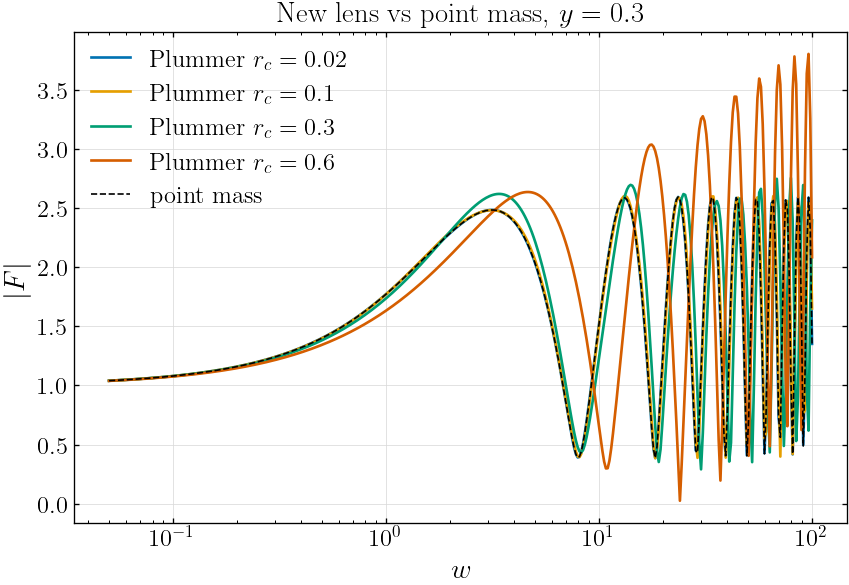

In [21]:
y = 0.3
ws = np.geomspace(0.05, 100, 400)

fig, ax = plt.subplots()
for rc in (0.02, 0.1, 0.3, 0.6):
    F = s1d.amplification_many(ws, y, plummer(1.0, rc))
    ax.semilogx(ws, np.abs(F), label=f"Plummer $r_c={rc}$")
F = s1d.amplification_many(ws, y, s1d.point_mass(1.0))
ax.semilogx(ws, np.abs(F), "k--", lw=1, label="point mass")
ax.set(xlabel="$w$", ylabel="$|F|$", title=f"New lens vs point mass, $y={y}$")
ax.legend(); plt.show()

New lenses combine with the built-ins in the usual way, e.g. a Plummer core inside an isothermal halo:

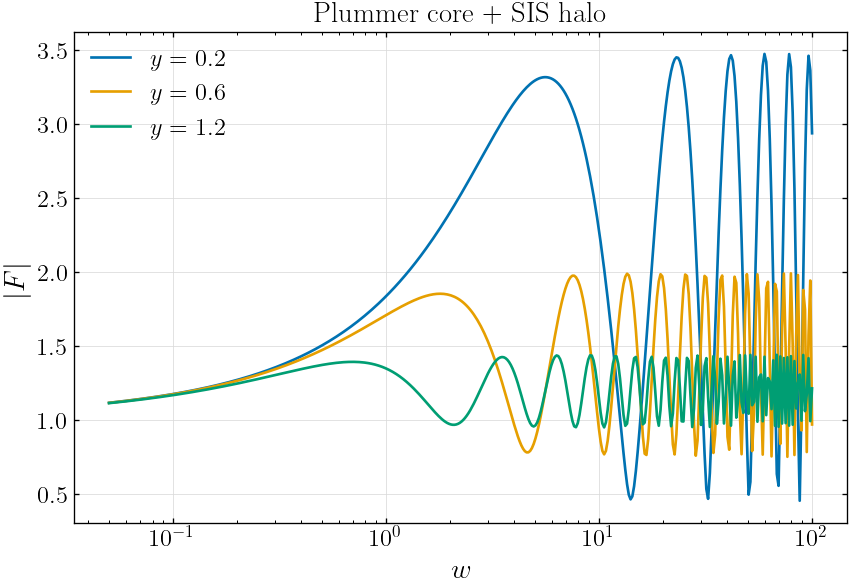

In [22]:
halo_plus_core = plummer(0.3, 0.05) + s1d.sis(0.5)

fig, ax = plt.subplots()
for y in (0.2, 0.6, 1.2):
    F = s1d.amplification_many(ws, y, halo_plus_core)
    ax.semilogx(ws, np.abs(F), label=f"$y={y}$")
ax.set(xlabel="$w$", ylabel="$|F|$", title="Plummer core + SIS halo")
ax.legend(); plt.show()

### 5.3 Step 3: what happens if `psi` is not analytic?

`Solver1D` calls `check_analytic()` automatically when it is built. A potential that uses `np.abs` looks fine on the real axis but is invalid on the rotated tail, and the check warns about it:

In [23]:
bad = s1d.Potential(lambda x: np.abs(x))        # NOT analytic

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    bad.check_analytic(verbose=True)
print("warning raised:", len(w) > 0)
if w:
    print(str(w[0].message)[:160], "...")

check_analytic: derivative mismatch 5.0e-01, Im psi 0.0e+00, psi_real 0.0e+00
warning raised: True
psi does not look analytic (derivative mismatch 5.0e-01, Im psi on the real axis 0.0e+00, psi_real vs psi 0.0e+00). Use only analytic numpy operations (no abs/h ...


**Checklist for a new lens**

1. Write `psi(x)` with analytic numpy operations (it must accept complex arrays).
2. Run `lens.check_analytic(verbose=True)`.
3. Compare against a known limit or a built-in lens (as in 5.1 and 5.2).
4. Optionally supply `psi_real` (speed) and `q_inf` (skips the numerical estimate).

## 6. Accuracy checks

Two ways to check a result:

* **against an analytic answer** (point mass), as in section 2.1;
* **with `estimate_error=True`**, which re-computes with the split point moved outward and more nodes and reports the difference. This works for any lens, including new ones.

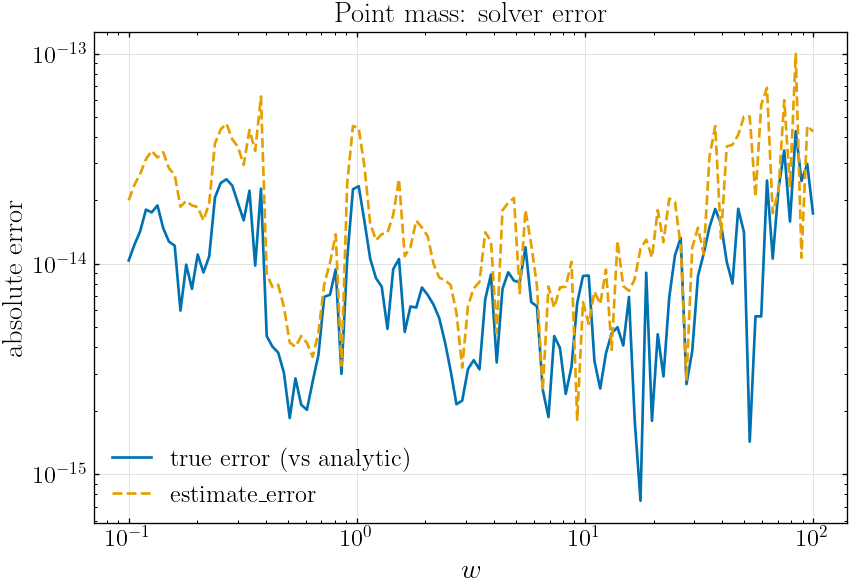

In [24]:
y = 0.5
ws = np.geomspace(0.1, 100, 120)

F, err = s1d.amplification_many(ws, y, s1d.point_mass(1.0), estimate_error=True)
F_ex = np.array([F_point_mass_exact(w, y) for w in ws])

fig, ax = plt.subplots()
ax.loglog(ws, np.abs(F - F_ex) + 1e-18, label="true error (vs analytic)")
ax.loglog(ws, err + 1e-18, "--", label="estimate_error")
ax.set(xlabel="$w$", ylabel="absolute error", title="Point mass: solver error")
ax.legend(); plt.show()

In [25]:
# the same check on a lens with no closed form
F_new, err_new = s1d.amplification_many(ws, y, plummer(1.0, 0.1), estimate_error=True)
print("Plummer: max estimated error =", err_new.max())

Plummer: max estimated error = 2.526026153546133e-13


## More?

* Interpolation in $w$ (`interpolate=True` / `'auto'`) for very many frequencies
* Parallel evaluation (`n_workers`, `close()`, context manager)
* Tuning accuracy vs speed (`ngl`, `nlag`, `n_cheb`, `PE_SETTINGS`)
* Using `Solver1D` inside a sampler (bilby)
* Comparison with other solvers (GLoW, `gwlens`)